# 1. Strike segmentation and spectral features

Turns the field recordings of 19 October 2025 into the set of strikes used by all analyses:

1. Reads the annotated interval of each zone (`data/annotation/zone_intervals.csv`).
2. Detects **peaks** of the envelope in the band above 4 kHz, where the contact of the hammer dominates and the
   resonance of the stone contributes little.
3. Accepts as a **strike** a peak that (a) falls within the interval of one zone; (b) has at least 30 % of the
   typical peak amplitude of its recording (75th percentile); (c) has no other peak within 0.35 s; and
   (d) excites at least one of the modes of the stone.
4. Cuts each strike (0.4 s from 5 ms before its maximum, 300 Hz high-pass) and computes its 15 spectral features.
5. Splits the recordings into a **characterisation set** and a **validation set** (section 1.3).

**Inputs:** WAV files in `data/raw/s2_2025-10-19_audio` and intervals in `data/annotation`.
**Outputs:** `intermediate/strikes.csv`, `intermediate/features.csv`, `tables/t01_strikes_per_zone.csv`,
`data/derived/recording_sets.csv`.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # folder with config.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config as C
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.4})
pd.set_option("display.precision", 2)

import librosa
from scipy import signal
from scipy.io import wavfile
warnings.filterwarnings("ignore", category=wavfile.WavFileWarning)
FS = C.FS

## 1.1 Annotated intervals

In [2]:
iv = pd.read_csv(C.ZONE_INTERVALS)
print(f"{len(iv)} intervals (zone × recording) in {iv.file.nunique()} recordings; zones {iv.zone.min()}–{iv.zone.max()}")
iv.head()

125 intervals (zone × recording) in 18 recordings; zones 1–24


,zone,file,start_s,end_s
0,1,20251019-135332.wav,2.98,7.70
1,2,20251019-135332.wav,9.28,14.20
2,3,20251019-135332.wav,15.48,19.85
3,4,20251019-135332.wav,22.70,27.95
4,5,20251019-135332.wav,29.34,35.10


## 1.2 Peak detection and criteria

The contact of the hammer produces a short, broadband sound. The signal is high-pass filtered above 4 kHz, its
envelope is taken (2 ms moving average), and peaks higher than the median + 40 median absolute deviations (MAD), with
a prominence > 20 MAD and at least 0.15 s apart, are searched for. The **strike maximum** is the largest |x|
(300 Hz high-pass) between −5 and +30 ms of the peak. A mode is **present** if, in the window from +30 ms to +0.4 s,
its peak exceeds 6 times the spectral median within ±40 Hz.

In [3]:
b4, a4 = signal.butter(4, 4000 / (FS / 2), "high")
b5, a5 = signal.butter(C.FILTER_ORDER, C.HIGHPASS_HZ / (FS / 2), "high")
N = 2 ** 16; fr = np.fft.rfftfreq(N, 1 / FS); MODES = np.array(C.REFERENCE_MODES)
SEP, AMP_THR = 0.35, 0.3             # double strike (s); minimum amplitude relative to the 75th percentile
MAD_THR, PROM_MAD, MIN_DIST = 40, 20, 0.15   # peak height and prominence (in MAD) and minimum spacing (s)
MODE_FACTOR = 6                      # a mode is present if its peak exceeds 6 times the local spectral median

def read(w):
    _, x = wavfile.read(C.AUDIO / w); return x.astype(np.float32).mean(axis=1)

rows, signals = [], {}
for w, dw in iv.groupby("file"):
    x = read(w)
    y = signal.filtfilt(b4, a4, x); env = np.convolve(np.abs(y), np.ones(96) / 96, "same")
    base = np.median(env); mad = np.median(np.abs(env - base))
    on, _ = signal.find_peaks(env, height=base + MAD_THR * mad, prominence=PROM_MAD * mad, distance=int(MIN_DIST * FS))
    xf = signal.filtfilt(b5, a5, x); signals[w] = xf
    for k, i in enumerate(on):
        t = i / FS
        zs = sorted(set(dw[(dw.start_s - 0.05 <= t) & (t <= dw.end_s)].zone))
        if not zs:
            continue
        a, b = i - int(0.005 * FS), i + int(0.03 * FS)
        pk = a + int(np.argmax(np.abs(xf[a:b])))
        s = xf[pk + int(0.03 * FS): pk + int(0.4 * FS)]; X = np.abs(np.fft.rfft(s * np.hanning(len(s)), N))
        nmod = sum(X[(fr > m - 6) & (fr < m + 6)].max() / np.median(X[(fr > m - 40) & (fr < m + 40) & ~((fr > m - 6) & (fr < m + 6))]) >= MODE_FACTOR for m in MODES)
        rows.append({"file": w, "t_s": round(t, 4), "i_peak": pk, "zones": ",".join(map(str, zs)),
                     "peak_amp": env[i], "modes_present": int(nmod)})
I = pd.DataFrame(rows)
I["amp_rel"] = I.peak_amp / I.groupby("file").peak_amp.transform(lambda v: np.percentile(v, 75))
I["above_amplitude"] = I.amp_rel >= AMP_THR
# double strike: another peak above the amplitude threshold within SEP s
strong = I[I.above_amplitude]
def double(r):
    o = strong[(strong.file == r.file) & (strong.t_s != r.t_s)]
    return bool((np.abs(o.t_s - r.t_s) < SEP).any())
I["double"] = I.apply(double, axis=1)
def reason(r):
    if "," in r.zones: return "intervals of two zones"
    if not r.above_amplitude: return "weak peak (not a strike)"
    if r.double: return "double strike (another peak < 0.35 s away)"
    if r.modes_present == 0: return "does not excite the stone modes"
    return "valid"
I["reason"] = I.apply(reason, axis=1)
print(f"{(I.reason == 'valid').sum()} strikes")

613 strikes


## 1.3 Strike table

613 strikes in 18 recordings and 24 zones
strikes per zone: 13–31 (median 28); recordings per zone: 3–6
zone–recording runs: 125; with 5 strikes: 110


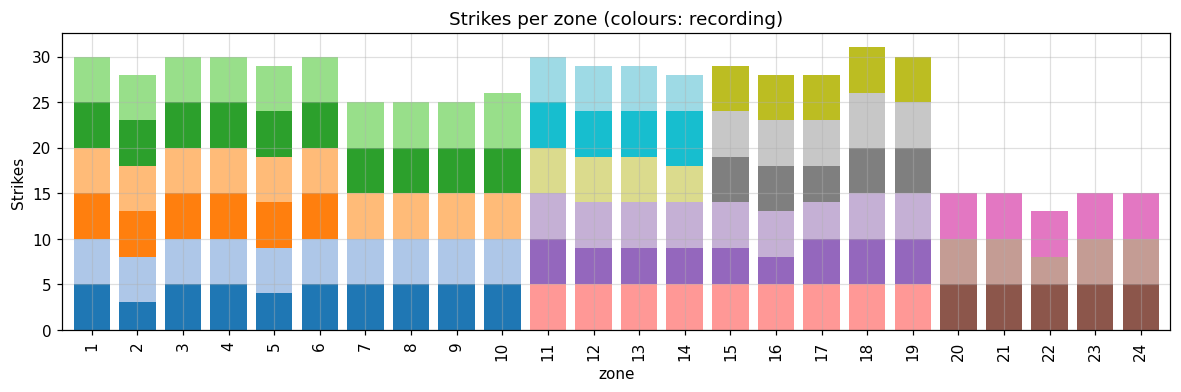

In [4]:
G = I[I.reason == "valid"].copy()
G["zone"] = G.zones.astype(int)
G = G.sort_values(["zone", "file", "t_s"]).reset_index(drop=True)
G["strike"] = G.groupby("zone").cumcount() + 1
G["run"] = G.groupby(["zone", "file"]).ngroup()
G = G[["zone", "strike", "file", "t_s", "i_peak", "amp_rel", "modes_present", "run"]]
tz = G.groupby("zone").agg(strikes=("t_s", "size"), recordings=("file", "nunique")).reset_index()
tz.to_csv(C.TABLES / "t01_strikes_per_zone.csv", index=False)
print(f"{len(G)} strikes in {G.file.nunique()} recordings and {G.zone.nunique()} zones")
print(f"strikes per zone: {tz.strikes.min()}–{tz.strikes.max()} (median {tz.strikes.median():.0f}); "
      f"recordings per zone: {tz.recordings.min()}–{tz.recordings.max()}")
nt = G.groupby(["zone", "file"]).size()
print(f"zone–recording runs: {len(nt)}; with 5 strikes: {(nt == 5).sum()}")
fig, ax = plt.subplots(figsize=(13, 3.5))
G.groupby(["zone", "file"]).size().unstack().plot.bar(stacked=True, ax=ax, legend=False, width=.8, colormap="tab20")
ax.set_ylabel("Strikes"); ax.set_title("Strikes per zone (colours: recording)")
plt.savefig(C.FIGURES / "fig01_strikes_per_zone.png", dpi=150, bbox_inches="tight"); plt.show()

### Strikes per run

A **run** is the series of consecutive strikes of one zone in one recording (one interval of `zone_intervals.csv`).
Each zone appears only once in each recording where it was struck, so the number of runs of a zone equals the number
of recordings in which it appears.

In [5]:
tt = G.groupby(["zone", "file"]).size().rename("strikes").reset_index()
tt.to_csv(C.TABLES / "t01_strikes_per_run.csv", index=False)
print(f"{len(tt)} runs; strikes per run: {tt.strikes.min()}–{tt.strikes.max()}")
print("Distribution (strikes per run → number of runs):", tt.strikes.value_counts().sort_index().to_dict())
print("Runs with 3 or 4 strikes:")
print(tt[tt.strikes < 5].to_string(index=False))
print("Runs per zone (= recordings per zone):", tt.groupby("zone").size().min(), "–", tt.groupby("zone").size().max())

125 runs; strikes per run: 3–6
Distribution (strikes per run → number of runs): {3: 3, 4: 9, 5: 110, 6: 3}
Runs with 3 or 4 strikes:
 zone                file  strikes
    2 20251019-135332.wav        3
    5 20251019-135332.wav        4
   12 20251019-141757.wav        4
   13 20251019-141757.wav        4
   14 20251019-141757.wav        4
   14 20251019-151007.wav        4
   14 20251019-151407.wav        4
   15 20251019-141757.wav        4
   16 20251019-141757.wav        3
   17 20251019-142014.wav        4
   17 20251019-150207.wav        4
   22 20251019-144016.wav        3
Runs per zone (= recordings per zone): 3 – 6


### Characterisation set and validation set

Of the 18 recordings, 15 have simultaneous accelerometer data (the first three, 135332, 135632 and 135829, were made
before the accelerometer was started). Eleven of them (`C.CHARACTERISATION_RECORDINGS`) are used to **characterise**
the sound; they were chosen so that every zone appears in at least two characterisation recordings and in at least
one validation recording. The remaining 7 recordings form the **validation set**, used only to test the zone
classifier (notebook 07) and the grouping of zones (notebook 12) on recordings not seen in the analysis. The split is
by recording, never by strike, because strikes from the same recording are more alike than strikes from different
recordings. New column: `set` (`characterisation` / `validation`).

In [6]:
acc_files = set(pd.read_csv(C.ACCELEROMETER / "files.csv").audio_recording)
G["set"] = np.where(G.file.isin(C.CHARACTERISATION_RECORDINGS), "characterisation", "validation")
G.to_csv(C.INTERMEDIATE / "strikes.csv", index=False)
Ch, Va = G[G.set == "characterisation"], G[G.set == "validation"]
assert Ch.file.isin(acc_files).all(), "all characterisation recordings have accelerometer data"
assert (Ch.groupby("zone").file.nunique() >= 2).all() and Ch.zone.nunique() == Va.zone.nunique() == G.zone.nunique()
span = lambda z: f"{min(z)}–{max(z)}" if list(z) == list(range(min(z), max(z) + 1)) else ",".join(map(str, z))
sets = (G.groupby("file").agg(set=("set", "first"), zones=("zone", lambda z: span(sorted(z.unique()))),
                              strikes=("zone", "size")).reset_index())
sets["accelerometer"] = sets.file.isin(acc_files)
sets = sets.sort_values(["set", "file"])
C.RECORDING_SETS.parent.mkdir(exist_ok=True); sets.to_csv(C.RECORDING_SETS, index=False)
print(f"Characterisation: {Ch.file.nunique()} recordings, {len(Ch)} strikes; recordings per zone "
      f"{Ch.groupby('zone').file.nunique().min()}–{Ch.groupby('zone').file.nunique().max()}; strikes per zone "
      f"{Ch.groupby('zone').size().min()}–{Ch.groupby('zone').size().max()}")
print(f"Validation: {Va.file.nunique()} recordings, {len(Va)} strikes, {Va.zone.nunique()} zones")
sets

Characterisation: 11 recordings, 371 strikes; recordings per zone 2–4; strikes per zone 10–20
Validation: 7 recordings, 242 strikes, 24 zones


,file,set,zones,strikes,accelerometer
3,20251019-140152.wav,characterisation,1–10,50,True
4,20251019-140412.wav,characterisation,1–10,50,True
5,20251019-140629.wav,characterisation,1–10,51,True
7,20251019-141757.wav,characterisation,11–19,39,True
8,20251019-142014.wav,characterisation,11–19,44,True
9,20251019-143811.wav,characterisation,20–24,25,True
11,20251019-144311.wav,characterisation,20–24,25,True
12,20251019-150207.wav,characterisation,15–19,24,True
14,20251019-150644.wav,characterisation,15–19,25,True
15,20251019-151007.wav,characterisation,11–14,19,True


### Review sheets: intervals and strikes in each recording

To audit the annotation, each recording is drawn with its waveform, the zone intervals of `zone_intervals.csv` and its
spectrogram (0–2500 Hz), with the detected strikes marked by red lines. The modes of the stone appear as horizontal
lines starting at each strike; the runs of the same zone share the same pattern of lines. The 18 sheets are saved in
`results/figures/review/`; one is shown here as an example.

In [7]:
REV = C.FIGURES / "review"; REV.mkdir(exist_ok=True)
for w in sorted(G.file.unique()):
    _, x = wavfile.read(C.AUDIO / w); x = x.astype(np.float32).mean(axis=1) / 32768
    t = np.arange(len(x)) / FS; gw = G[G.file == w]; iw = iv[iv.file == w]
    fig, ax = plt.subplots(3, 1, figsize=(14, 6.5), sharex=True, gridspec_kw={"height_ratios": [1.2, 0.5, 1.6]})
    ax[0].plot(t[::4], x[::4], lw=.3, color="0.3"); ax[0].set_ylabel("audio"); ax[0].set_ylim(-1, 1)
    for _, r in iw.iterrows():
        col = plt.cm.tab20((r.zone - 1) % 20)
        ax[1].axvspan(r.start_s, r.end_s, color=col, alpha=.6)
        ax[1].text((r.start_s + r.end_s) / 2, .5, f"Z{r.zone}\n{(gw.zone == r.zone).sum()} strikes", ha="center", va="center", fontsize=8)
    ax[1].set_yticks([]); ax[1].set_ylabel("zone")
    f_, t_, S = signal.spectrogram(x, FS, nperseg=4096, noverlap=3072)
    k = f_ <= 2500
    ax[2].pcolormesh(t_, f_[k], 10 * np.log10(S[k] + 1e-14), cmap="magma", shading="auto", vmin=-130, vmax=-60, rasterized=True)
    ax[2].set_ylabel("Hz"); ax[2].set_xlabel("time (s)")
    for a in (ax[0], ax[2]):
        for tg in gw.i_peak / FS:
            a.axvline(tg, color="r", lw=.6, alpha=.8)
    ax[0].set_title(f"{w} · {len(gw)} strikes in {gw.zone.nunique()} zones (red lines)", loc="left")
    plt.tight_layout(); plt.savefig(REV / f"review_{w[:-4]}.png", dpi=90, bbox_inches="tight"); plt.close(fig)
print(f"{len(list(REV.glob('review_*.png')))} sheets in {REV.relative_to(C.ROOT)}")

18 sheets in results/figures/review


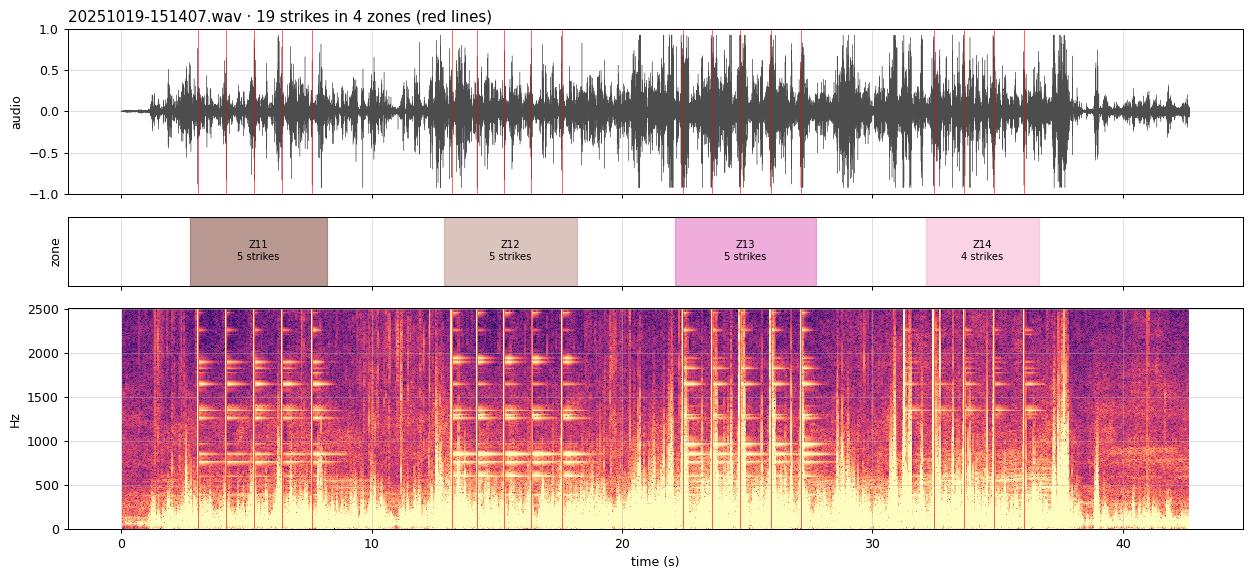

In [8]:
# Example: recording of zones 11–14 (the other sheets are in results/figures/review/)
from IPython.display import Image
Image(filename=str(REV / "review_20251019-151407.png"))

## 1.4 Segments and spectral features

Segment of 0.4 s (19 200 samples) from 5 ms before the strike maximum, 300 Hz high-pass signal (below 300 Hz the wind
dominates; this keeps the lowest mode, at 384.9 Hz); spectral centroid, spectral bandwidth and MFCC 0–12 with
`librosa`, averaged over the frames.

In [9]:
def features(y):
    y = y.astype(np.float64)
    d = {"spectral_centroid": np.mean(librosa.feature.spectral_centroid(y=y, sr=FS)),
         "spectral_bandwidth": np.mean(librosa.feature.spectral_bandwidth(y=y, sr=FS))}
    for i, v in enumerate(librosa.feature.mfcc(y=y, sr=FS, n_mfcc=C.N_MFCC).mean(axis=1)):
        d[f"mfcc_{i}"] = v
    return d

feat = []
for _, r in G.iterrows():
    a = r.i_peak - int(C.PRE_PEAK * FS)
    feat.append({"zone": r.zone, "strike": r.strike, "file": r.file, "t_s": r.t_s, "set": r.set,
                 **features(signals[r.file][a:a + C.STRIKE_SAMPLES])})
F = pd.DataFrame(feat)
F.to_csv(C.INTERMEDIATE / "features.csv", index=False)
print(F.shape)
F.groupby("zone")[["spectral_centroid", "spectral_bandwidth"]].mean().round(0).T

(613, 20)


zone,1,2,3,4,5,6,7,8,9,10,...,15,16,17,18,19,20,21,22,23,24
spectral_centroid,1509.0,1580.0,1992.0,1952.0,2055.0,1989.0,1944.0,1831.0,1718.0,1517.0,...,1838.0,1693.0,1702.0,1543.0,1596.0,1709.0,1568.0,1401.0,1728.0,1623.0
spectral_bandwidth,2044.0,2444.0,2537.0,2478.0,2821.0,2546.0,2795.0,2113.0,2293.0,1704.0,...,2675.0,2428.0,2485.0,2167.0,2383.0,2085.0,1925.0,1830.0,1673.0,1775.0


## 1.5 Supplement: the detection criteria in one recording and the choice of thresholds

This section does not change the result: it applies the criteria of section 1.2 again to (1) show, in one recording,
how the signal becomes accepted strikes and rejected peaks, and (2) show with the data of the 18 recordings why the
thresholds were chosen and how much the number of strikes depends on them.

In [10]:
# Envelope > 4 kHz of each recording (the same as in section 1.2), with its median and MAD
ENV = {}
for w in iv.file.unique():
    y = signal.filtfilt(b4, a4, read(w)); env = np.convolve(np.abs(y), np.ones(96) / 96, "same")
    base = np.median(env); ENV[w] = (env, base, np.median(np.abs(env - base)))

def mode_ratios(w, i):
    """Peak / local spectral median of each reference mode for the peak at sample i."""
    xf = signals[w]; a = i - int(0.005 * FS); pk = a + int(np.argmax(np.abs(xf[a:i + int(0.03 * FS)])))
    s = xf[pk + int(0.03 * FS): pk + int(0.4 * FS)]; X = np.abs(np.fft.rfft(s * np.hanning(len(s)), N))
    r = []
    for m in MODES:
        c = (fr > m - 6) & (fr < m + 6)
        r.append(X[c].max() / np.median(X[(fr > m - 40) & (fr < m + 40) & ~c]))
    return np.array(r)

_MR = {}
def detect(k_mad=MAD_THR, p_mad=PROM_MAD, dist=MIN_DIST, thr=AMP_THR, sep=SEP, factor=MODE_FACTOR):
    """Repeats the criteria of section 1.2 with the given thresholds; returns the peaks and whether they are valid strikes."""
    rows = []
    for w, dw in iv.groupby("file"):
        env, base, mad = ENV[w]
        on, _ = signal.find_peaks(env, height=base + k_mad * mad, prominence=p_mad * mad, distance=int(dist * FS))
        for i in on:
            t = i / FS; zs = set(dw[(dw.start_s - 0.05 <= t) & (t <= dw.end_s)].zone)
            if zs:
                rows.append((w, i, t, len(zs), env[i], (env[i] - base) / mad))
    D = pd.DataFrame(rows, columns=["file", "i", "t", "n_zones", "amp", "k_mad"])
    D["amp_rel"] = D.amp / D.groupby("file").amp.transform(lambda v: np.percentile(v, 75))
    D["above_amplitude"] = D.amp_rel >= thr
    D["neighbour_s"] = np.inf       # time to the nearest peak (amp_rel >= thr) of the same recording
    for w, d in D.groupby("file"):
        tf = d.t[d.above_amplitude].values
        D.loc[d.index, "neighbour_s"] = [np.min(np.abs(tf[tf != t] - t), initial=np.inf) for t in d.t]
    D["double"] = D.neighbour_s < sep
    D["n_modes"] = [int((_MR.setdefault((w, i), mode_ratios(w, i)) >= factor).sum()) for w, i in zip(D.file, D.i)]
    D["valid"] = (D.n_zones == 1) & D.above_amplitude & ~D.double & (D.n_modes > 0)
    return D

D0 = detect()
assert D0.valid.sum() == len(G), "the repetition does not reproduce the strikes of section 1.3"
print(f"{len(D0)} peaks in the intervals, {D0.valid.sum()} valid strikes (same as in 1.3)")

675 peaks in the intervals, 613 valid strikes (same as in 1.3)


### One recording step by step

Recording 20251019-135332 (zones 1–10). (a) Signal high-pass filtered at 4 kHz: almost only the contact of the hammer
remains. (b) Envelope (2 ms moving average, log scale) with the median of the recording (background level), the
detection threshold median + 40 MAD and the relative threshold of 30 % of the 75th percentile of the peaks; the
coloured bands are the zone intervals. (c) Signal high-pass filtered at 300 Hz (the one analysed) with the accepted
strikes and the rejected peaks by reason. Bottom: detail of one example of each kind of rejection.

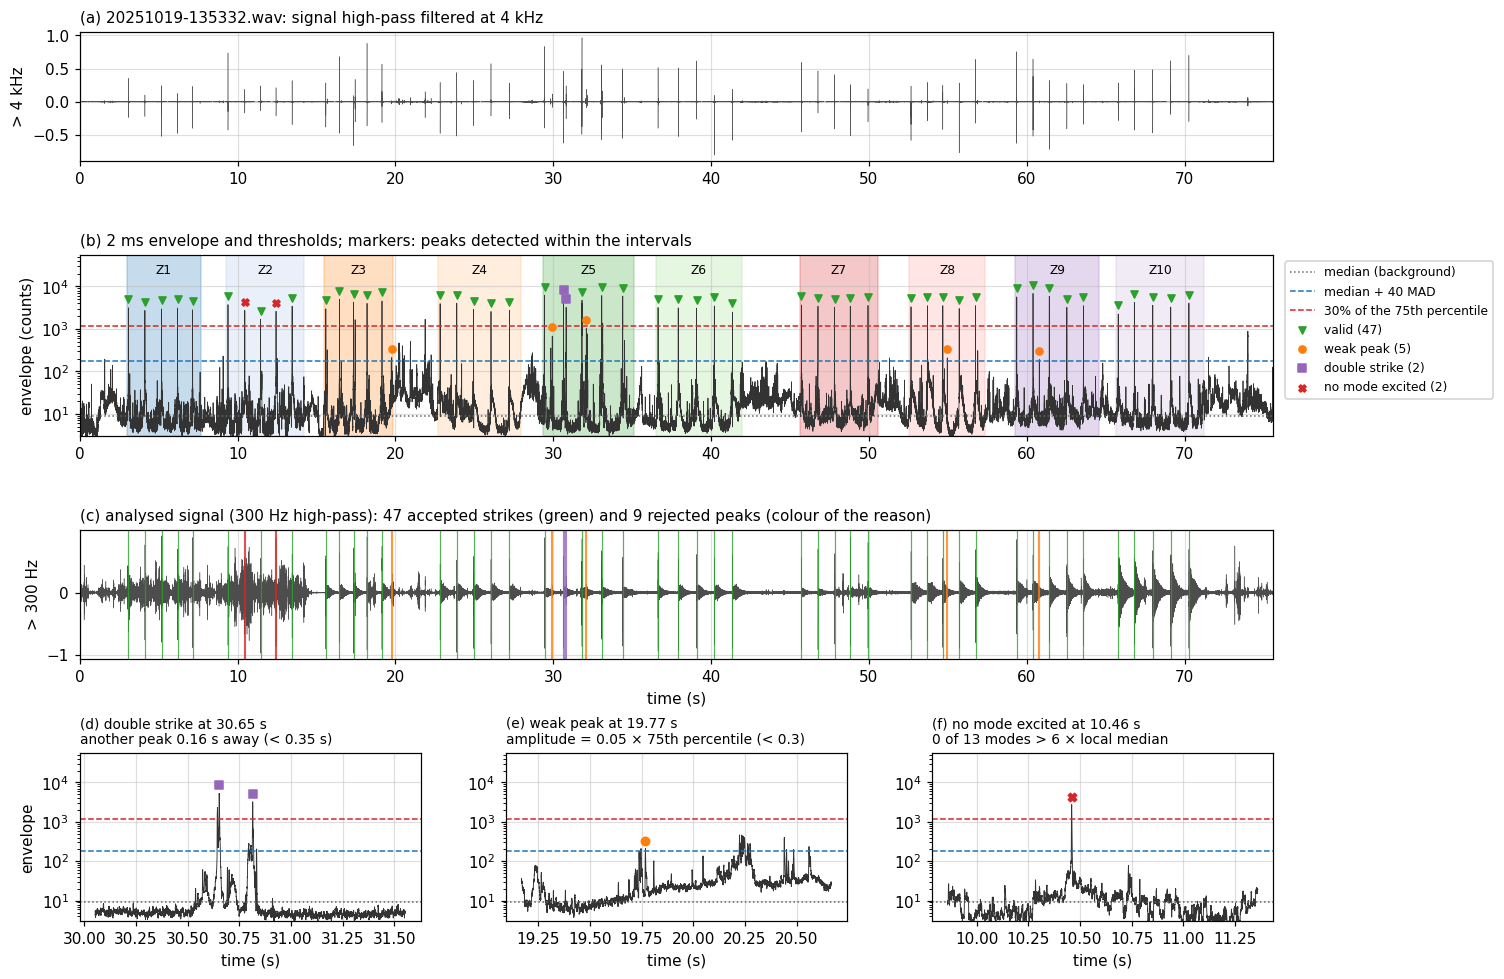

reason
valid              47
weak peak           5
no mode excited     2
double strike       2


In [11]:
EXAMPLE = "20251019-135332.wav"
env, base, mad = ENV[EXAMPLE]; x = read(EXAMPLE); y4 = signal.filtfilt(b4, a4, x); x3 = signals[EXAMPLE]
t = np.arange(len(x)) / FS; Dw = D0[D0.file == EXAMPLE].copy(); iw = iv[iv.file == EXAMPLE]
rel_thr = AMP_THR * np.percentile(Dw.amp, 75)
def reason_d(r):
    if r.n_zones > 1: return "intervals of two zones"
    if not r.above_amplitude: return "weak peak"
    if r.double: return "double strike"
    if r.n_modes == 0: return "no mode excited"
    return "valid"
Dw["reason"] = Dw.apply(reason_d, axis=1)
STYLE = {"valid": ("tab:green", "v"), "weak peak": ("tab:orange", "o"), "double strike": ("tab:purple", "s"),
         "no mode excited": ("tab:red", "X"), "intervals of two zones": ("tab:brown", "D")}

def env_max(e, step=48):     # block maximum, to draw the envelope without losing the peaks
    n = len(e) // step; return np.arange(n) * step / FS, e[:n * step].reshape(n, step).max(axis=1)

def threshold_lines(ax):
    ax.axhline(base, color="0.4", ls=":", lw=1, label="median (background)")
    ax.axhline(base + MAD_THR * mad, color="tab:blue", ls="--", lw=1, label=f"median + {MAD_THR} MAD")
    ax.axhline(rel_thr, color="tab:red", ls="--", lw=1, label=f"{AMP_THR:.0%} of the 75th percentile")

fig = plt.figure(figsize=(14, 10.5))
gs = fig.add_gridspec(4, 3, height_ratios=[1, 1.4, 1, 1.3], hspace=0.62, wspace=0.25)
a0 = fig.add_subplot(gs[0, :]); a1 = fig.add_subplot(gs[1, :], sharex=a0); a2 = fig.add_subplot(gs[2, :], sharex=a0)
a0.plot(t[::4], y4[::4] / 32768, lw=.3, color="0.3"); a0.set_ylabel("> 4 kHz")
a0.set_title(f"(a) {EXAMPLE}: signal high-pass filtered at 4 kHz", loc="left", fontsize=10)
te, ee = env_max(env); a1.semilogy(te, np.maximum(ee, base / 3), lw=.5, color="0.2")
threshold_lines(a1)
for _, r in iw.iterrows():
    a1.axvspan(r.start_s, r.end_s, color=plt.cm.tab20((r.zone - 1) % 20), alpha=.25)
    a1.text((r.start_s + r.end_s) / 2, env.max() * 3, f"Z{r.zone}", ha="center", fontsize=8)
for m, (c, mk) in STYLE.items():
    d = Dw[Dw.reason == m]
    if len(d): a1.scatter(d.t, d.amp * 1.6, color=c, marker=mk, s=22, zorder=3, label=f"{m} ({len(d)})")
a1.set_ylim(base / 3, env.max() * 8); a1.set_ylabel("envelope (counts)")
a1.legend(loc="upper left", bbox_to_anchor=(1.005, 1), fontsize=8, framealpha=.9)
a1.set_title("(b) 2 ms envelope and thresholds; markers: peaks detected within the intervals", loc="left", fontsize=10)
a2.plot(t[::4], x3[::4] / 32768, lw=.3, color="0.3"); a2.set_ylabel("> 300 Hz"); a2.set_xlabel("time (s)")
for m, (c, mk) in STYLE.items():
    for tt in Dw[Dw.reason == m].t: a2.axvline(tt, color=c, lw=.8 if m == "valid" else 1.4, alpha=.8)
a2.set_title(f"(c) analysed signal (300 Hz high-pass): {(Dw.reason == 'valid').sum()} accepted strikes (green) and "
             f"{(Dw.reason != 'valid').sum()} rejected peaks (colour of the reason)", loc="left", fontsize=10)
a0.set_xlim(0, t[-1])
for j, m in enumerate(["double strike", "weak peak", "no mode excited"]):
    ax = fig.add_subplot(gs[3, j]); d = Dw[Dw.reason == m]
    if not len(d): ax.set_axis_off(); continue
    r = d.iloc[0]; a, b = int((r.t - .6) * FS), int((r.t + .9) * FS)
    ax.semilogy(t[a:b], np.maximum(env[a:b], base / 3), lw=.6, color="0.2"); threshold_lines(ax)
    near = Dw[(Dw.t > r.t - .6) & (Dw.t < r.t + .9)]
    for _, v in near.iterrows():
        c, mk = STYLE[v.reason]; ax.scatter(v.t, v.amp * 1.6, color=c, marker=mk, s=30, zorder=3)
    det = {"double strike": f"another peak {r.neighbour_s:.2f} s away (< {SEP} s)",
           "weak peak": f"amplitude = {r.amp_rel:.2f} × 75th percentile (< {AMP_THR})",
           "no mode excited": f"0 of {len(MODES)} modes > {MODE_FACTOR} × local median"}[m]
    ax.set_title(f"({'def'[j]}) {m} at {r.t:.2f} s\n{det}", loc="left", fontsize=9)
    ax.set_ylim(base / 3, env.max() * 8); ax.set_xlabel("time (s)")
    if j == 0: ax.set_ylabel("envelope")
plt.savefig(C.FIGURES / "fig01_detection_example.png", dpi=150, bbox_inches="tight"); plt.show()
print(Dw.reason.value_counts().to_string())

### Why these thresholds?

The peaks of the 18 recordings are pooled. (a) Height of all envelope peaks within the intervals (from 3 MAD), in MAD
above the median. (b) Amplitude of each detected peak relative to the 75th percentile of its recording. (c) Time from
each peak to the nearest peak of its recording. (d) Number of valid strikes when one of the thresholds is multiplied by
a factor between 1/8 and 8, the others being kept at their values.

(a) 1965 peaks > 3 MAD in the intervals; the 613 valid strikes have 329–3623 MAD (1st percentile: 396); peaks between 40 MAD and the weakest valid strike: 51
(b) weak peaks: relative amplitude 0.020–0.30; valid strikes: 0.31–1.71; peaks between 0.15 and 0.30: 6
(c) between peaks: 2 at < 0.35 s (double strikes); the rest at ≥ 0.86 s; valid strikes: minimum spacing 0.86 s, median 1.18 s


(d) valid strikes when each threshold is multiplied by the factor of the column:
                          1/8  1/4  1/2    1    2    4    8
height (40 MAD)           613  613  613  613  613  613  613
prominence (20 MAD)       613  613  613  613  613  613  613
peak spacing (0.15 s)     612  612  612  613  614  614  433
relative amplitude (0.3)  604  609  615  613  542   52    0
double strike (0.35 s)    615  615  613  613  613   35    1
mode present (6 ×)        619  619  619  613  598  568  521


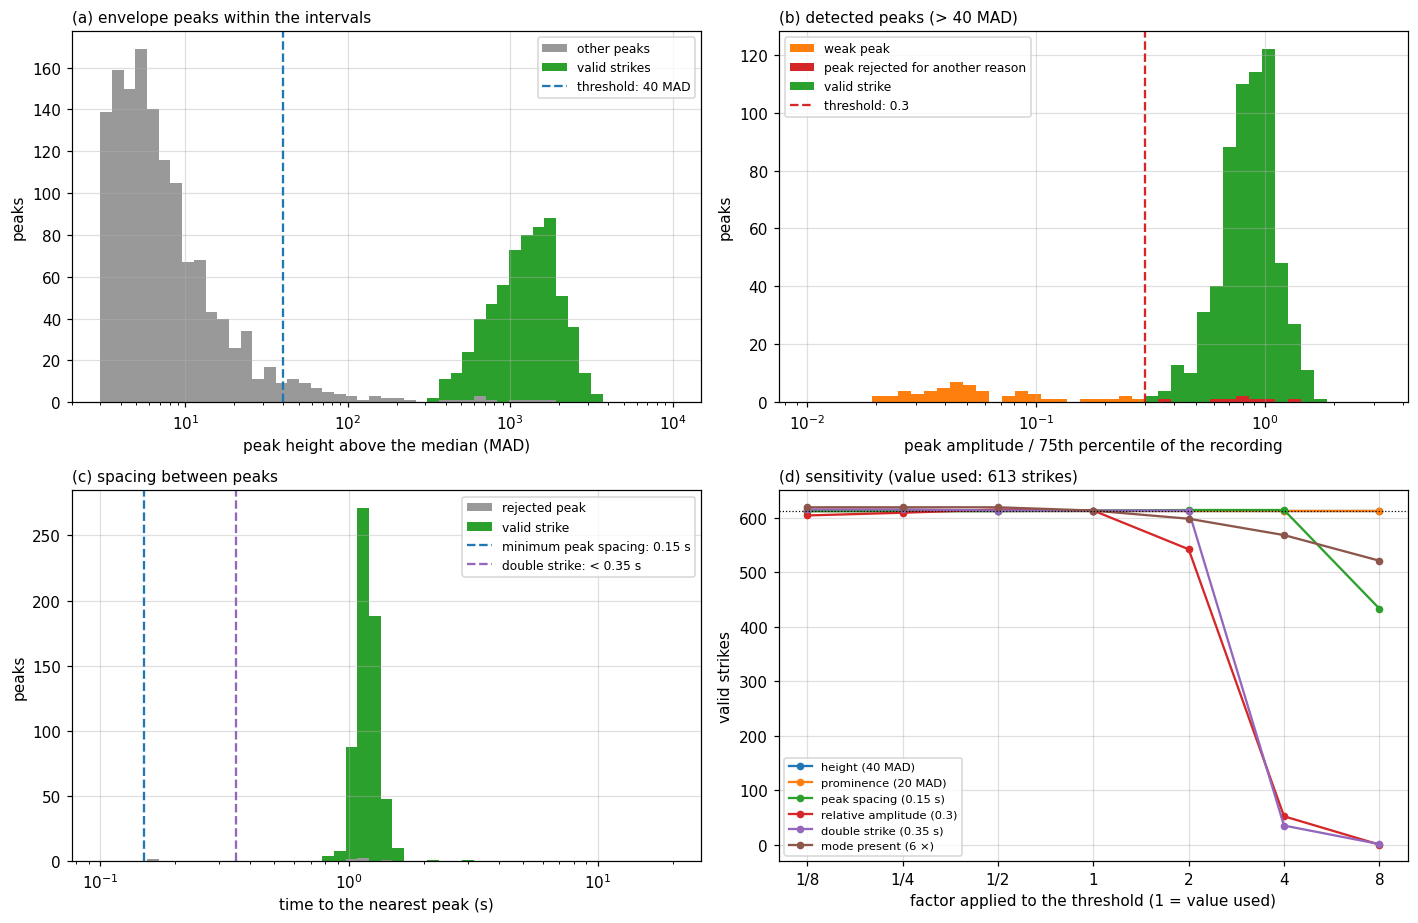

In [12]:
# (a) all envelope peaks within the intervals, from 3 MAD
P = []
for w, dw in iv.groupby("file"):
    env, base, mad = ENV[w]
    on, _ = signal.find_peaks(env, height=base + 3 * mad, distance=int(MIN_DIST * FS))
    for i in on:
        t_ = i / FS
        if ((dw.start_s - 0.05 <= t_) & (t_ <= dw.end_s)).any():
            P.append((w, i, (env[i] - base) / mad))
P = pd.DataFrame(P, columns=["file", "i", "k_mad"])
P["valid"] = P.set_index(["file", "i"]).index.isin(D0[D0.valid].set_index(["file", "i"]).index)
V = D0[D0.valid]
print(f"(a) {len(P)} peaks > 3 MAD in the intervals; the {len(V)} valid strikes have {V.k_mad.min():.0f}–{V.k_mad.max():.0f} MAD "
      f"(1st percentile: {np.percentile(V.k_mad, 1):.0f}); peaks between {MAD_THR} MAD and the weakest valid strike: "
      f"{((P.k_mad >= MAD_THR) & (P.k_mad < V.k_mad.min())).sum()}")
r = D0.amp_rel; rd = D0[~D0.above_amplitude].amp_rel
print(f"(b) weak peaks: relative amplitude {rd.min():.3f}–{rd.max():.2f}; valid strikes: {V.amp_rel.min():.2f}–{V.amp_rel.max():.2f}; "
      f"peaks between 0.15 and 0.30: {((r >= 0.15) & (r < 0.30)).sum()}")
vi = D0[D0.above_amplitude]
print(f"(c) between peaks: {(vi.neighbour_s < SEP).sum()} at < {SEP} s (double strikes); the rest at ≥ {vi.neighbour_s[vi.neighbour_s >= SEP].min():.2f} s; "
      f"valid strikes: minimum spacing {V.neighbour_s.min():.2f} s, median {V.neighbour_s.median():.2f} s")

# (d) sensitivity: each threshold multiplied by a factor
FACT = [1/8, 1/4, 1/2, 1, 2, 4, 8]
NAMES = {"k_mad": f"height ({MAD_THR} MAD)", "p_mad": f"prominence ({PROM_MAD} MAD)",
         "dist": f"peak spacing ({MIN_DIST} s)", "thr": f"relative amplitude ({AMP_THR})",
         "sep": f"double strike ({SEP} s)", "factor": f"mode present ({MODE_FACTOR} ×)"}
NOMINAL = {"k_mad": MAD_THR, "p_mad": PROM_MAD, "dist": MIN_DIST, "thr": AMP_THR, "sep": SEP, "factor": MODE_FACTOR}
S = pd.DataFrame({p: [int(detect(**{p: v * f}).valid.sum()) for f in FACT] for p, v in NOMINAL.items()}, index=FACT)
S.index = ["1/8", "1/4", "1/2", "1", "2", "4", "8"]
S.rename(columns=NAMES).T.to_csv(C.TABLES / "t01_threshold_sensitivity.csv")
print("(d) valid strikes when each threshold is multiplied by the factor of the column:")
print(S.rename(columns=NAMES).T.to_string())

fig, ax = plt.subplots(2, 2, figsize=(13, 8.5)); ax = ax.ravel()
bins = np.logspace(np.log10(3), 4, 50)
ax[0].hist([P[~P.valid].k_mad, P[P.valid].k_mad], bins=bins, stacked=True, color=["0.6", "tab:green"],
           label=["other peaks", "valid strikes"])
ax[0].axvline(MAD_THR, color="tab:blue", ls="--", label=f"threshold: {MAD_THR} MAD")
ax[0].set_xscale("log"); ax[0].set_xlabel("peak height above the median (MAD)"); ax[0].set_ylabel("peaks")
ax[0].set_title("(a) envelope peaks within the intervals", loc="left", fontsize=10); ax[0].legend(fontsize=8)
bins = np.logspace(-2, 0.5, 45)
ax[1].hist([D0[~D0.above_amplitude].amp_rel, D0[D0.above_amplitude & ~D0.valid].amp_rel, V.amp_rel], bins=bins, stacked=True,
           color=["tab:orange", "tab:red", "tab:green"], label=["weak peak", "peak rejected for another reason", "valid strike"])
ax[1].axvline(AMP_THR, color="tab:red", ls="--", label=f"threshold: {AMP_THR}")
ax[1].set_xscale("log"); ax[1].set_xlabel("peak amplitude / 75th percentile of the recording"); ax[1].set_ylabel("peaks")
ax[1].set_title(f"(b) detected peaks (> {MAD_THR} MAD)", loc="left", fontsize=10); ax[1].legend(fontsize=8)
bins = np.logspace(np.log10(0.1), np.log10(20), 50)
ax[2].hist([vi[~vi.valid].neighbour_s, V.neighbour_s], bins=bins, stacked=True, color=["0.6", "tab:green"],
           label=["rejected peak", "valid strike"])
ax[2].axvline(MIN_DIST, color="tab:blue", ls="--", label=f"minimum peak spacing: {MIN_DIST} s")
ax[2].axvline(SEP, color="tab:purple", ls="--", label=f"double strike: < {SEP} s")
ax[2].set_xscale("log"); ax[2].set_xlabel("time to the nearest peak (s)"); ax[2].set_ylabel("peaks")
ax[2].set_title("(c) spacing between peaks", loc="left", fontsize=10); ax[2].legend(fontsize=8)
for p in S.columns:
    ax[3].plot(FACT, S[p].values, "o-", ms=4, label=NAMES[p])
ax[3].axhline(len(G), color="k", lw=.8, ls=":"); ax[3].set_xscale("log", base=2)
ax[3].set_xticks(FACT); ax[3].set_xticklabels(S.index)
ax[3].set_xlabel("factor applied to the threshold (1 = value used)"); ax[3].set_ylabel("valid strikes")
ax[3].set_title(f"(d) sensitivity (value used: {len(G)} strikes)", loc="left", fontsize=10); ax[3].legend(fontsize=7.5)
plt.tight_layout(); plt.savefig(C.FIGURES / "fig01_thresholds.png", dpi=150, bbox_inches="tight"); plt.show()

**4 kHz high-pass and 2 ms envelope.** The modes of the stone lie between 385 and 1938 Hz and wind dominates below
300 Hz; above 4 kHz almost only the short, broadband contact of the hammer remains (panel a of the previous figure).
The 2 ms moving average (96 samples) turns each contact into a single peak and is much shorter than the spacing
between strikes (≥ 0.86 s).

**Median and MAD as background level.** The peaks take up a tiny fraction of each recording, so the median and the
median absolute deviation (MAD) of the envelope measure the background (wind and surroundings) without being affected
by the strikes. Expressing the thresholds in MAD makes them equivalent in recordings with different background levels.

**Height > median + 40 MAD and prominence > 20 MAD (panel a).** The 613 valid strikes form a separate group, between
329 and 3623 MAD (1st percentile: 396 MAD); most other peaks are background fluctuations below 40 MAD. The threshold
lies almost an order of magnitude below the weakest valid strike: it is a generous first screen that loses no strikes
and also lets weak peaks through (51 peaks between 40 MAD and the weakest valid strike), which are separated in the
next step. The result therefore does not depend on its value: heights from 5 to 320 MAD and prominences from 2.5 to
160 MAD give the same 613 strikes (panel d). The prominence avoids counting oscillations of one peak as separate peaks.

**Minimum spacing of 0.15 s between peaks (panel c).** Ensures a single peak per contact of the hammer and is much
smaller than the spacing between consecutive strikes (minimum 0.86 s, median 1.18 s). Between 0.02 and 0.6 s the
number of strikes changes by at most 1 (612–614); only at 1.2 s, comparable to the spacing between strikes, are
strikes lost.

**Amplitude ≥ 30 % of the 75th percentile of the recording (panel b).** The relative amplitude of the peaks is
bimodal: weak peaks range from 0.02 to 0.30 and valid strikes from 0.31 to 1.71; the threshold lies in the sparsely
populated region between the two groups (6 peaks between 0.15 and 0.30). The 75th percentile, not the maximum, is
used so that an exceptionally strong strike does not shift the threshold, and a per-recording reference is used
because the gain and the strike level change between recordings. With thresholds from 0.04 to 0.15 the number of
strikes ranges from 604 to 615; at 0.6 real strikes are already discarded (542).

**Double strike: another peak within 0.35 s.** Each strike is analysed in a 0.4 s window, and a second peak inside it
would mix two excitations. Only 2 peaks have another one within 0.35 s; all others are 0.86 s or more apart, so any
value between 0.18 and 0.7 s gives the same 613 strikes.

**Mode present: peak > 6 times the local spectral median (≈ 16 dB).** Discards peaks that do not set the stone
vibrating (2 in the example recording). It is the most gradual criterion: with factors from 3 to 12 the number of
strikes ranges from 619 to 598 (+1.0 % to −2.4 %), and from 0.75 to 48 from 619 to 521.

**In summary:** except for the relative amplitude at twice its value (0.6: −12 %), no threshold at half or twice its
value changes the number of strikes by more than 2.4 %. The height, prominence, spacing and double-strike thresholds
lie in empty regions of their distributions; the relative-amplitude threshold in the sparsely populated region between
weak peaks and strikes; and the mode-present criterion only excludes peaks without any clear mode.